# SGD, Adam, and AdamW from scratch
### ECON 524 — Big Data Econometrics · Lab supplement

**One clarification before we start.** Adam and AdamW are *not* "two learning rates." They use the
same learning rate $\rho$ and the same adaptive step. The only difference is **where the
weight-decay term enters the update**. That distinction is the whole point of this notebook, and it
turns out to be a genuinely econometric point: it is about *how a penalty gets rescaled* by an
adaptive algorithm.

So we separate two knobs that are easy to conflate:

| Knob | What it controls | Section |
|---|---|---|
| $\rho$ (learning rate) | how far each step moves | §3 |
| $\lambda$ (weight decay) | how hard the penalty pulls weights to zero | §5 |

**Plan.** Everything is written as a flat loop over mini-batches — no helper functions, no classes —
so every line maps to one line of algebra.

1. Simulated rental data (§1)
2. The gradient, by hand (§2)
3. Plain SGD and the role of $\rho$ (§3)
4. Adam from scratch (§4)
5. Adam-with-$L_2$ vs. AdamW (§5) — the main event
6. The same thing with `torch.optim`, reproducing the from-scratch numbers to machine precision (§6)
7. The lecture-slide pipeline: `MLP` + `DataLoader` + early stopping (§7)
8. Sources and flagged uncertainties (§8)

In [1]:
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

print("numpy", np.__version__, "| torch", torch.__version__)

numpy 2.0.2 | torch 2.8.0


---
## 1. Data: Atlanta student rentals

Made up, but built to look like a listings scrape. Rent is measured in **hundreds of dollars**
so the coefficients are readable.

$$\text{rent}_i = 12 + 0.8\,\text{beds}_i - 0.5\,\text{miles}_i + 0.25\,\text{sqft100}_i + \varepsilon_i,
\qquad \varepsilon_i \sim N(0,1)$$

One design choice matters a lot later: **the three regressors are on deliberately different scales.**

| Regressor | Units | Std. dev. |
|---|---|---|
| `beds` | bedrooms | $\approx 0.8$ |
| `miles` | miles to campus | $\approx 1.5$ |
| `sqft100` | hundreds of sq ft | $\approx 5.0$ |

That 6-to-1 spread in scale is not cosmetic. The gradient with respect to $w_j$ carries a factor of
$z_{ij}$, so **a regressor on a 6× larger scale produces gradients on a 6× larger scale.** Every
adaptive method in this notebook reacts to that, and §5 shows it quietly distorting a penalty.

We center the regressors (so the intercept is just mean rent) but we do **not** standardize them —
standardizing would erase the very thing we want to look at.

In [2]:
rng = np.random.default_rng(524)
n = 600

beds    = rng.normal(2.0, 0.8, n)     # bedrooms
miles   = rng.normal(3.0, 1.5, n)     # miles to campus
sqft100 = rng.normal(9.0, 5.0, n)     # hundreds of square feet

Z_raw = np.column_stack([beds, miles, sqft100])
beta_true = np.array([0.8, -0.5, 0.25])
y = 12.0 + Z_raw @ beta_true + rng.normal(0, 1.0, n)   # rent in $100s

Z = Z_raw - Z_raw.mean(axis=0)        # center only; do NOT standardize

names = ["beds", "miles", "sqft100"]
Z_train, y_train = Z[:450], y[:450]
Z_valid, y_valid = Z[450:], y[450:]

print("mean rent  $%.0f" % (100 * y.mean()))
print("column sds", np.round(Z.std(axis=0), 2))
print("train/valid", Z_train.shape[0], "/", Z_valid.shape[0])

mean rent  $1429
column sds [0.75 1.48 4.93]
train/valid 450 / 150


/var/folders/ys/lyk1c3594szgx8f2prks44w40000gn/T/ipykernel_6313/3447018697.py:10: RuntimeWarning: divide by zero encountered in matmul
  y = 12.0 + Z_raw @ beta_true + rng.normal(0, 1.0, n)   # rent in $100s
/var/folders/ys/lyk1c3594szgx8f2prks44w40000gn/T/ipykernel_6313/3447018697.py:10: RuntimeWarning: overflow encountered in matmul
  y = 12.0 + Z_raw @ beta_true + rng.normal(0, 1.0, n)   # rent in $100s
/var/folders/ys/lyk1c3594szgx8f2prks44w40000gn/T/ipykernel_6313/3447018697.py:10: RuntimeWarning: invalid value encountered in matmul
  y = 12.0 + Z_raw @ beta_true + rng.normal(0, 1.0, n)   # rent in $100s


### The target we are chasing

The population object is $\beta$. The sample object every algorithm below is actually trying to hit
is the **OLS fit on the training data** — that is the exact minimizer of the training MSE. Keep this
row of numbers in view; it is the answer key for §3, §4 and §6.

In [3]:
X_train = np.column_stack([np.ones(450), Z_train])
ols = np.linalg.lstsq(X_train, y_train, rcond=None)[0]

print("          intercept    beds     miles   sqft100")
print("truth        12.000   0.800   -0.500     0.250   (uncentered intercept)")
print("OLS       %8.3f %7.3f %8.3f %9.3f" % tuple(ols))

          intercept    beds     miles   sqft100
truth        12.000   0.800   -0.500     0.250   (uncentered intercept)
OLS         14.263   0.730   -0.501     0.244


---
## 2. The gradient, by hand

With $p$ regressors, parameters $w \in \mathbb{R}^p$ and intercept $b$, the mini-batch MSE over a
batch $\mathcal{B}$ of size $B$ is

$$L_{\mathcal{B}}(w, b) = \frac{1}{B}\sum_{i \in \mathcal{B}} \big(z_i'w + b - y_i\big)^2.$$

Differentiating, with residual $r_i = z_i'w + b - y_i$:

$$\nabla_w L_{\mathcal{B}} = \frac{2}{B} Z_{\mathcal{B}}' r,
\qquad
\frac{\partial L_{\mathcal{B}}}{\partial b} = \frac{2}{B} \sum_{i \in \mathcal{B}} r_i.$$

**Where the "stochastic" comes from.** $\nabla L_{\mathcal{B}}$ is an *unbiased estimator* of the
full-sample gradient when $\mathcal{B}$ is drawn at random:
$\mathbb{E}[\nabla L_{\mathcal{B}}] = \nabla L$. SGD is a stochastic-approximation scheme in the
sense of **Robbins & Monro (1951)** — we are solving $\nabla L(w) = 0$ while only ever observing a
noisy estimate of $\nabla L$. That is the original idea, and it predates machine learning by four
decades: it is the same logic as a method-of-moments estimator chasing $\mathbb{E}[g(w)] = 0$ with
sample moments.

The factor of $2$ is not decoration. PyTorch's `nn.MSELoss()` is the plain mean of squared errors,
with no $1/2$, so keeping the $2$ is exactly what makes §6 match to machine precision.

In [4]:
# One gradient evaluation, written out. Nothing is hidden in a function.
w = np.zeros(3)
b = 0.0
idx = np.arange(64)                      # a batch of 64 listings

resid   = Z_train[idx] @ w + b - y_train[idx]
grad_w  = (2 / len(idx)) * (Z_train[idx].T @ resid)
grad_b  = (2 / len(idx)) * resid.sum()

print("batch MSE ", round((resid ** 2).mean(), 3))
print("grad_w    ", np.round(grad_w, 2))
print("grad_b    ", round(grad_b, 2))

batch MSE  211.121
grad_w     [ -0.79   4.65 -21.88]
grad_b     -28.79


Look at `grad_w`: the three entries span more than an order of magnitude. Two things drive
that — the column scales from §1, and how strongly each regressor happens to covary with the current
residual. **A single scalar step size $\rho$ has to serve all three coordinates at once.** That
tension is what §3 runs into and what §4 fixes.

---
## 3. Plain SGD, and what $\rho$ actually does

The update is one line:

$$\begin{pmatrix} w \\ b \end{pmatrix}
\leftarrow
\begin{pmatrix} w \\ b \end{pmatrix}
- \rho \, \nabla L_{\mathcal{B}}.$$

**The mathematical intuition.** Near the minimum the loss is quadratic with Hessian $H = 2\,\hat{E}[zz']$,
and the error contracts coordinate-wise at rate $|1 - \rho \mu_k|$ along each eigendirection with
eigenvalue $\mu_k$. Two consequences fall straight out:

- **Stability** needs $\rho < 2/\mu_{\max}$. Above that, $|1-\rho\mu_{\max}| > 1$ and the iterate
  explodes — geometrically, not gently.
- **Speed** is set by $\mu_{\min}$: the slowest direction contracts at $|1-\rho\mu_{\min}|$.

So a *single* $\rho$ is squeezed between the largest and smallest curvature. The gap between them —
the condition number $\mu_{\max}/\mu_{\min}$ — is the binding constraint, and in our data it comes
straight from the 6-to-1 spread in column scales.

One more classical point: with a **constant** $\rho$, SGD does not converge to the minimizer. It
converges to a *noise ball* around it, of radius $O(\rho)$, because the gradient noise never
disappears. Robbins & Monro's original conditions, $\sum_t \rho_t = \infty$ and
$\sum_t \rho_t^2 < \infty$, are precisely what rules this out — the first keeps you moving far
enough, the second kills the noise. Everything below uses a constant $\rho$, so expect the last
digit or two to jitter.

In [5]:
# Shared batch schedule: every algorithm in this notebook sees the SAME batches,
# in the SAME order. That is what makes the comparisons clean.
EPOCHS = 600
BATCH  = 64
sched_rng = np.random.default_rng(0)
perms = [sched_rng.permutation(450) for _ in range(EPOCHS)]

print("steps per epoch", int(np.ceil(450 / BATCH)), "| total steps", EPOCHS * int(np.ceil(450 / BATCH)))

steps per epoch 8 | total steps 4800


In [6]:
rhos = [0.00005, 0.002, 0.02, 0.05]
sgd_paths = {}
sgd_final = {}

np.seterr(all="ignore")       # rho = 0.05 overflows on purpose; we detect it below
for rho in rhos:
    w = np.zeros(3)
    b = 0.0
    path = []
    for perm in perms:
        for s in range(0, 450, BATCH):
            idx = perm[s:s + BATCH]
            resid  = Z_train[idx] @ w + b - y_train[idx]
            grad_w = (2 / len(idx)) * (Z_train[idx].T @ resid)
            grad_b = (2 / len(idx)) * resid.sum()
            w = w - rho * grad_w          # the entire algorithm
            b = b - rho * grad_b
        full = ((Z_train @ w + b - y_train) ** 2).mean()   # training MSE this epoch
        path.append(full)
        if not np.isfinite(full):         # diverged; stop before overflowing to nan
            break
    path += [np.inf] * (EPOCHS - len(path))
    sgd_paths[rho] = np.array(path)
    sgd_final[rho] = (w.copy(), b)

print("OLS training MSE = %.4f   (the floor)\n" % ((X_train @ ols - y_train) ** 2).mean())
for rho in rhos:
    w, b = sgd_final[rho]
    p = sgd_paths[rho]
    # average over the last 50 epochs: with a constant step the iterate never stops
    # jittering, so a single epoch is not a fair summary of where it settled.
    tag = "DIVERGED" if not np.isfinite(p).all() else "settled MSE %7.4f" % p[-50:].mean()
    print("rho = %-8g %-22s b = %s" % (rho, tag, "%10.3f" % b if abs(b) < 1e6 else "  overflowed"))

OLS training MSE = 1.0164   (the floor)

rho = 5e-05    settled MSE 82.2610    b =      5.433
rho = 0.002    settled MSE  1.0200    b =     14.258
rho = 0.02     settled MSE  1.4102    b =     14.260
rho = 0.05     DIVERGED               b =   overflowed


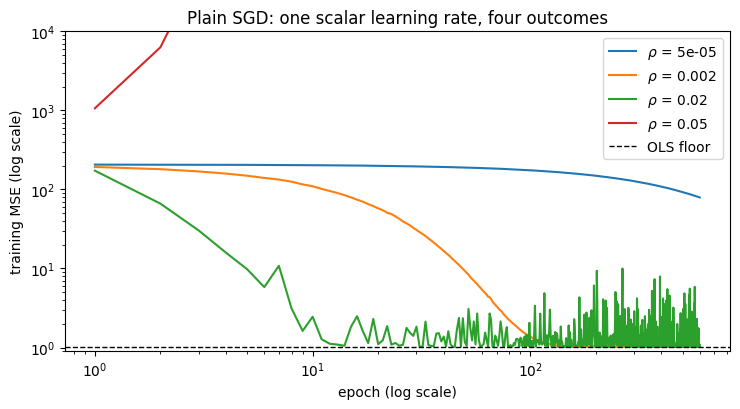

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
floor = ((X_train @ ols - y_train) ** 2).mean()
for rho in rhos:
    p = np.where(np.isfinite(sgd_paths[rho]), sgd_paths[rho], np.nan)
    ax.plot(np.arange(1, EPOCHS + 1), p, label=r"$\rho$ = %g" % rho)
ax.axhline(floor, ls="--", c="k", lw=1, label="OLS floor")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(0.9, 1e4)
ax.set_xlabel("epoch (log scale)"); ax.set_ylabel("training MSE (log scale)")
ax.set_title("Plain SGD: one scalar learning rate, four outcomes")
ax.legend(); fig.tight_layout(); plt.show()

**Reading the figure.**

- $\rho = 5\times10^{-5}$: stable but still descending after 600 epochs, stuck around MSE $82$.
  $\rho\mu_{\min}$ is tiny, so the slow direction has barely contracted.
- $\rho = 0.002$: converges to MSE $1.020$, essentially the OLS floor of $1.016$.
- $\rho = 0.02$: **descends fastest of all, and settles worst** — around MSE $1.41$, visibly above
  the slower rate. This is the $O(\rho)$ noise ball made visible: a bigger step buys speed and pays
  for it with a permanently noisier resting place. It is exactly the behaviour Robbins & Monro's
  $\sum_t\rho_t^2 < \infty$ condition exists to rule out.
- $\rho = 0.05$: unstable from the start. The training MSE never descends at all, and after ~200
  epochs of geometric growth the iterate overflows.

So "fastest" and "most accurate" are not the same rate — the usual resolution in practice is a
decaying schedule, fast early and small late.

Notice there is no "safe large $\rho$" here. The usable window is narrow *because* the regressors are
on different scales. In a classical econometrics course the standard fix would be to standardize $Z$.
Adam's answer is different and more interesting: **let every coordinate carry its own step size.**

---
## 4. Adam from scratch

Adam (**Kingma & Ba, 2015**) is an assembly of three earlier ideas, and it is worth naming them
separately because each one is doing a distinct job:

1. **Momentum** — an exponentially weighted average of past gradients, $m_t$. Descends from
   **Polyak's (1964) heavy-ball** method. It averages out mini-batch noise and builds speed along
   directions of consistent sign.
2. **Per-coordinate scaling** — divide by $\sqrt{v_t}$, a running average of *squared* gradients.
   This is the **AdaGrad** idea (**Duchi, Hazan & Singer, 2011**), with AdaGrad's ever-growing sum
   replaced by **RMSProp's** exponential average (**Tieleman & Hinton, 2012**) so the step does not
   decay to zero.
3. **Bias correction** — the $1/(1-\beta^t)$ factors, which are Adam's own contribution.

$$
\begin{aligned}
m_t &= \beta_1 m_{t-1} + (1-\beta_1) g_t, &\qquad \hat{m}_t &= m_t / (1-\beta_1^t),\\
v_t &= \beta_2 v_{t-1} + (1-\beta_2) g_t^2, &\qquad \hat{v}_t &= v_t / (1-\beta_2^t),\\
\theta_t &= \theta_{t-1} - \rho \, \hat{m}_t / (\sqrt{\hat{v}_t} + \epsilon). & &
\end{aligned}
$$

**Why bias correction exists.** Start at $m_0 = 0$. Unrolling the recursion with stationary gradients,
$\mathbb{E}[m_t] = (1-\beta_1^t)\,\mathbb{E}[g]$ — the average is shrunk toward the zero it was
initialized at. Dividing by $(1-\beta_1^t)$ undoes exactly that shrinkage. With $\beta_2 = 0.999$ the
distortion in $v_t$ lasts hundreds of steps, so this is not a rounding detail; without it the first
few hundred steps are far too large.

**Why the step is scale-free.** $\hat{m}_t/\sqrt{\hat{v}_t}$ is a ratio of a first moment to a square
root of a second moment, so rescaling a regressor by $c$ rescales $g_j$ by $c$ and leaves the ratio
unchanged. The per-coordinate step size is bounded by roughly $\rho$ regardless of units. **That is
why Adam shrugs off the conditioning problem that §3 ran into** — and the reason $\rho = 10^{-3}$ is
a sane default across wildly different problems.

Since all three gradient coordinates here are of comparable sign-consistency, the ratio also tells
you something read-as-a-t-statistic: $\hat m/\sqrt{\hat v}$ is near $\pm 1$ when the gradient is
consistently signed, and near $0$ when it is pure noise.

In [8]:
rho, beta1, beta2, eps = 0.01, 0.9, 0.999, 1e-8

w, b = np.zeros(3), 0.0
m_w, v_w = np.zeros(3), np.zeros(3)
m_b, v_b = 0.0, 0.0
t = 0

for perm in perms:
    for s in range(0, 450, BATCH):
        idx = perm[s:s + BATCH]
        t += 1
        resid  = Z_train[idx] @ w + b - y_train[idx]
        grad_w = (2 / len(idx)) * (Z_train[idx].T @ resid)
        grad_b = (2 / len(idx)) * resid.sum()

        m_w = beta1 * m_w + (1 - beta1) * grad_w          # momentum
        v_w = beta2 * v_w + (1 - beta2) * grad_w ** 2     # squared-gradient average
        m_b = beta1 * m_b + (1 - beta1) * grad_b
        v_b = beta2 * v_b + (1 - beta2) * grad_b ** 2

        mhat_w = m_w / (1 - beta1 ** t)                   # bias correction
        vhat_w = v_w / (1 - beta2 ** t)
        mhat_b = m_b / (1 - beta1 ** t)
        vhat_b = v_b / (1 - beta2 ** t)

        w = w - rho * mhat_w / (np.sqrt(vhat_w) + eps)
        b = b - rho * mhat_b / (np.sqrt(vhat_b) + eps)

print("Adam      b = %7.4f  w = %s" % (b, np.round(w, 4)))
print("OLS       b = %7.4f  w = %s" % (ols[0], np.round(ols[1:], 4)))
print()
print("sqrt(vhat) per coordinate:", np.round(np.sqrt(vhat_w), 2), " <- note the spread")

Adam      b = 14.2572  w = [ 0.7401 -0.4925  0.2436]
OLS       b = 14.2632  w = [ 0.7295 -0.5008  0.2442]

sqrt(vhat) per coordinate: [0.7  1.25 4.44]  <- note the spread


Adam reproduces OLS to about three decimals, at $\rho = 0.01$ — a rate that would have been
sluggish for plain SGD — and with no scaling of the regressors.

Now look at the last line. $\sqrt{\hat v}$ differs by roughly **6×** across coordinates, inherited
directly from the column scales. Inside Adam that is harmless: it is exactly the rescaling that makes
the step uniform. **In §5 that same divisor lands on a penalty term, and there it is not harmless at
all.**

---
## 5. Adam + $L_2$ vs. AdamW — where the two actually differ

### 5.1 The classical equivalence, and where it breaks

Two ways to shrink coefficients toward zero:

**(a) Penalize the objective** (ridge — **Hoerl & Kennard, 1970**; the same Tikhonov regularization
behind the LASSO's $\ell_1$ cousin in Lecture 1). Minimize
$L(w) + \tfrac{\lambda}{2}\lVert w \rVert^2$, so the gradient picks up $+\lambda w$.

**(b) Decay the weights directly** (**Hanson & Pratt, 1988**). After each step, multiply $w$ by
something slightly less than one.

For **plain gradient descent** these are the same thing. Substitute (a) into the SGD update:

$$w \leftarrow w - \rho\big(\nabla L + \lambda w\big) = \underbrace{(1 - \rho\lambda)}_{\text{a shrink factor}} w - \rho \nabla L .$$

The penalty *is* a decay, with decay rate $\rho\lambda$. This is the classical equivalence (see
**Krogh & Hertz, 1992**), and it is why the two names got used interchangeably for thirty years.

**Loshchilov & Hutter (2019)** pointed out that the equivalence is an artifact of the update being
a bare multiple of the gradient. Push (a) through Adam instead. The penalty enters $g_t$, so it is
carried along into $m_t$ and $v_t$ and then **divided by $\sqrt{\hat v_t}$**:

$$w \leftarrow w - \rho \frac{\widehat{\big(m \text{ built from } \nabla L + \lambda w\big)}}{\sqrt{\hat v} + \epsilon}.$$

The shrinkage applied to coordinate $j$ is no longer $\rho\lambda$. It is approximately

$$\boxed{\;\rho \cdot \frac{\lambda}{\sqrt{\hat v_j} + \epsilon}\;}$$

**A coordinate-specific penalty that nobody chose.** It is set by the historical gradient magnitude
of that coordinate — which, per §1, is mostly a fact about *units*. Regressors with large gradients
get *weakly* penalized; regressors with small gradients get *hammered*.

AdamW's fix is to take the decay out of the gradient entirely and apply it to the weights directly:

$$w \leftarrow \underbrace{(1 - \rho\lambda)\,w}_{\text{decoupled, identical for all } j} - \rho \frac{\hat m}{\sqrt{\hat v} + \epsilon}.$$

**In one sentence:** Adam-with-$L_2$ puts the penalty where the adaptive rescaler can get at it;
AdamW puts it where the rescaler cannot.

### 5.2 Two loops, differing by two lines

Below, `decoupled=False` is `torch.optim.Adam(..., weight_decay=λ)` and `decoupled=True` is
`torch.optim.AdamW(..., weight_decay=λ)`. We do **not** decay the intercept — the ridge convention
from Lecture 1, where the penalty applies to slopes only. (Flagged in §8: PyTorch's default *does*
decay every parameter you hand it; we use parameter groups in §6 to match.)

In [9]:
# lambda is deliberately larger than a realistic default so the mechanism is visible.
results = {}

for lam in [0.0, 0.3, 0.6]:
    for decoupled in [False, True]:
        w, b = np.zeros(3), 0.0
        m_w, v_w = np.zeros(3), np.zeros(3)
        m_b, v_b = 0.0, 0.0
        t = 0
        for perm in perms:
            for s in range(0, 450, BATCH):
                idx = perm[s:s + BATCH]
                t += 1
                resid  = Z_train[idx] @ w + b - y_train[idx]
                grad_w = (2 / len(idx)) * (Z_train[idx].T @ resid)
                grad_b = (2 / len(idx)) * resid.sum()

                if decoupled:
                    w = w - rho * lam * w          # ---- AdamW: decay applied straight to w
                else:
                    grad_w = grad_w + lam * w      # ---- Adam + L2: decay folded into the gradient

                m_w = beta1 * m_w + (1 - beta1) * grad_w
                v_w = beta2 * v_w + (1 - beta2) * grad_w ** 2
                m_b = beta1 * m_b + (1 - beta1) * grad_b
                v_b = beta2 * v_b + (1 - beta2) * grad_b ** 2

                w = w - rho * (m_w / (1 - beta1 ** t)) / (np.sqrt(v_w / (1 - beta2 ** t)) + eps)
                b = b - rho * (m_b / (1 - beta1 ** t)) / (np.sqrt(v_b / (1 - beta2 ** t)) + eps)

        results[(lam, decoupled)] = (w.copy(), b, np.sqrt(v_w / (1 - beta2 ** t)))

for lam in [0.0, 0.3, 0.6]:
    wa, ba, vhat = results[(lam, False)]
    ww, bw, _    = results[(lam, True)]
    print("lambda = %.1f" % lam)
    print("   Adam + L2   w = %s   b = %.4f" % (np.round(wa, 4), ba))
    print("   AdamW       w = %s   b = %.4f" % (np.round(ww, 4), bw))

lambda = 0.0
   Adam + L2   w = [ 0.7401 -0.4925  0.2436]   b = 14.2572
   AdamW       w = [ 0.7401 -0.4925  0.2436]   b = 14.2572
lambda = 0.3
   Adam + L2   w = [ 0.5865 -0.4618  0.2407]   b = 14.2548
   AdamW       w = [ 0.616  -0.4546  0.2353]   b = 14.2554
lambda = 0.6
   Adam + L2   w = [ 0.4855 -0.4349  0.2384]   b = 14.2533
   AdamW       w = [ 0.5173 -0.4184  0.2273]   b = 14.2541


### 5.3 The effective penalty each coefficient actually received

This is the table the whole notebook is built around. Column $j$ of the first row is
$\lambda / (\sqrt{\hat v_j} + \epsilon)$; the second row is just $\lambda$.

Before reading it, compare $\sqrt{\hat v_j}$ to the column standard deviations from §1,
$(0.75,\ 1.48,\ 4.93)$. The ratios are nearly identical. **The divisor Adam built is, to a very
good approximation, just the units of the regressors.**

In [10]:
lam = 0.3
_, _, vhat = results[(lam, False)]     # vhat already holds sqrt(v_hat), one entry per coordinate
eff_adam = lam / (vhat + eps)          # the per-coordinate decay rate Adam+L2 actually applied

print("lambda = %.1f,  rho = %.3f\n" % (lam, rho))
print("                        %8s %8s %8s" % tuple(names))
print("sqrt(vhat_j)          : %8.2f %8.2f %8.2f" % tuple(vhat))
print("Adam+L2 decay rate    : %8.3f %8.3f %8.3f   <- set by units, not by you" % tuple(eff_adam))
print("AdamW   decay rate    : %8.3f %8.3f %8.3f   <- what you asked for" % tuple(np.full(3, lam)))
print("\nspread, Adam+L2: %.1fx between hardest- and softest-penalized coefficient"
      % (eff_adam.max() / eff_adam.min()))
print("spread, AdamW  : 1.0x")

lambda = 0.3,  rho = 0.010

                            beds    miles  sqft100
sqrt(vhat_j)          :     0.70     1.25     4.47
Adam+L2 decay rate    :    0.426    0.239    0.067   <- set by units, not by you
AdamW   decay rate    :    0.300    0.300    0.300   <- what you asked for

spread, Adam+L2: 6.3x between hardest- and softest-penalized coefficient
spread, AdamW  : 1.0x


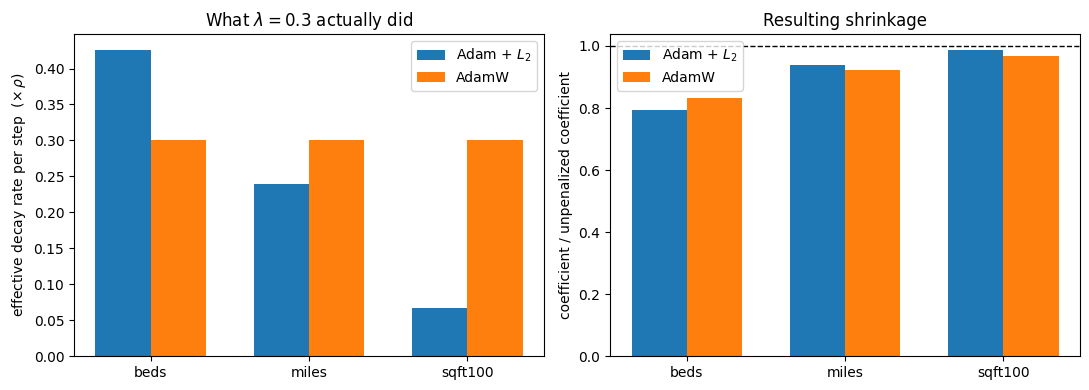

In [11]:
w0 = results[(0.0, False)][0]           # unpenalized Adam reference
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0))
x = np.arange(3); wd = 0.35

axes[0].bar(x - wd/2, eff_adam, wd, label="Adam + $L_2$")
axes[0].bar(x + wd/2, np.full(3, lam), wd, label="AdamW")
axes[0].set_xticks(x); axes[0].set_xticklabels(names)
axes[0].set_ylabel(r"effective decay rate per step  ($\times\,\rho$)")
axes[0].set_title(r"What $\lambda = %.1f$ actually did" % lam); axes[0].legend()

axes[1].bar(x - wd/2, results[(lam, False)][0] / w0, wd, label="Adam + $L_2$")
axes[1].bar(x + wd/2, results[(lam, True)][0]  / w0, wd, label="AdamW")
axes[1].axhline(1.0, c="k", lw=1, ls="--")
axes[1].set_xticks(x); axes[1].set_xticklabels(names)
axes[1].set_ylabel("coefficient / unpenalized coefficient")
axes[1].set_title("Resulting shrinkage"); axes[1].legend()
fig.tight_layout(); plt.show()

**What to take from the two panels — and what not to.**

*Left panel (the mechanism).* Under AdamW every slope is decayed at the same rate, $\rho\lambda$:
three bars of equal height, which is what "I set $\lambda = 0.3$" ought to mean. Under Adam-with-$L_2$
the three bars differ by about **6×**, ordered by column scale. `sqft100` — the largest-scale, most
informative regressor — is penalized least; `beds` is penalized hardest. Nothing in the code asked for
that ordering. It is a unit artifact that leaked through the adaptive divisor.

*Right panel (the consequence).* The resulting coefficients move in the predicted direction —
Adam-with-$L_2$ shrinks `beds` harder and leaves `sqft100` almost untouched, while AdamW's shrinkage
is more even. But **be honest about the size**: the coefficient gap here is modest, a few percentage
points, far less dramatic than the 6× gap in decay rates.

Why the gap compresses: at the stationary point, shrinkage stops where decay balances the *normalized*
gradient $\hat m/\sqrt{\hat v}$ — which is itself scale-free. So the data's restoring force partly
offsets the distorted penalty. With three well-identified regressors and $n = 450$ there is a strong
restoring force. The reason this matters in practice is that in high dimensions, with many weakly
identified parameters and a weak restoring force, the distortion is what survives — which is the
regime where Loshchilov & Hutter found AdamW's generalization gains.

**The practical upshot for your work:** under Adam-with-$L_2$, the $\lambda$ you tune is not portable
— rescale a regressor, or change architecture, and the realized penalty changes underneath you. Under
AdamW, $\lambda$ means the same thing for every parameter. That is a reproducibility argument as much
as a performance one.

---
## 6. The same thing with `torch.optim`

Now we replace the hand-written update with PyTorch and check that **we get the same numbers**.

Three things must line up for the match to be exact:

1. **Same model.** `nn.Linear(3, 1)` is exactly $z'w + b$. (The slide code's `MLP` is a different
   model — we get to it in §7.)
2. **Same batches.** The slide code uses `DataLoader(..., shuffle=True)`, which draws its *own*
   randomness. To compare like with like we feed PyTorch the same `perms` schedule by hand. The
   `DataLoader` itself appears in §7, as in the slides.
3. **Same treatment of the intercept.** We exclude the bias from decay via parameter groups, matching
   §5.

We also run in `float64`; in `float32` the match would be exact to about 1e-7 instead of 1e-16.

In [12]:
Z_t = torch.tensor(Z_train, dtype=torch.float64)
y_t = torch.tensor(y_train, dtype=torch.float64)
loss_fn = nn.MSELoss()           # plain mean of squared errors -- matches our 2/B factor

for kind, decoupled in [("Adam", False), ("AdamW", True)]:
    model = nn.Linear(3, 1, dtype=torch.float64)
    with torch.no_grad():
        model.weight.zero_(); model.bias.zero_()      # same start as the numpy loop

    Opt = torch.optim.AdamW if decoupled else torch.optim.Adam
    optimizer = Opt(
        [{"params": [model.weight], "weight_decay": lam},
         {"params": [model.bias],   "weight_decay": 0.0}],   # intercept not penalized
        lr=rho, betas=(beta1, beta2), eps=eps,
    )

    for perm in perms:
        for s in range(0, 450, BATCH):
            idx = perm[s:s + BATCH]
            pred = model(Z_t[idx]).squeeze(-1)
            loss = loss_fn(pred, y_t[idx])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

    w_torch = model.weight.detach().numpy().ravel()
    b_torch = model.bias.item()
    w_np, b_np, _ = results[(lam, decoupled)]

    print("%-6s torch   w = %s  b = %.6f" % (kind, np.round(w_torch, 6), b_torch))
    print("%-6s scratch w = %s  b = %.6f" % ("", np.round(w_np, 6), b_np))
    print("%-6s max|difference|  w: %.2e   b: %.2e\n"
          % ("", np.abs(w_torch - w_np).max(), abs(b_torch - b_np)))

Adam   torch   w = [ 0.5865   -0.461824  0.240659]  b = 14.254818
       scratch w = [ 0.5865   -0.461824  0.240659]  b = 14.254818
       max|difference|  w: 0.00e+00   b: 0.00e+00

AdamW  torch   w = [ 0.615971 -0.454621  0.235335]  b = 14.255413
       scratch w = [ 0.615971 -0.454621  0.235335]  b = 14.255413
       max|difference|  w: 1.11e-16   b: 0.00e+00



Agreement at the level of floating-point round-off. The from-scratch loops are not an
approximation of `torch.optim` — they are the same algorithm.

This is also a useful empirical check on a convention: PyTorch's AdamW multiplies the decay by the
learning rate, $\theta \leftarrow \theta - \gamma\lambda\theta$. Our `w = w - rho * lam * w` matches,
which is why the numbers agree. See §8 — other libraries do not all make that choice.

---
## 7. The lecture-slide pipeline

Same data, but now the model is the `MLP` from the slides, with `DataLoader`, dropout and early
stopping. Two changes from the exact-match section, both standard practice and both worth saying
out loud:

- **Inputs and target are standardized.** With $\rho = 10^{-3}$ and a few hundred epochs, a network
  starting near zero simply cannot travel to a target whose mean is $14.3$. Standardizing removes
  the problem; we convert the validation MSE back to $\$100^2$ at the end.
- **`shuffle=True`**, as in the slides. So this run is *not* bit-identical to anything above — nor
  should it be, since the model class is different.

Early stopping deserves a sentence of its own. It is a regularizer: stopping before the training
loss bottoms out keeps the fitted function in a smaller effective class, which is the same
bias-variance trade the $\lambda$ in §5 buys by a different route. The `copy.deepcopy` on
`best_state` is load-bearing — `state_dict()` returns references to live tensors, so without the
copy the saved "best" weights would be silently overwritten by later updates.

In [13]:
sz, my, sy = Z_train.std(axis=0), y_train.mean(), y_train.std()
to_t = lambda a: torch.tensor(a, dtype=torch.float32)
Z_tr_s, Z_va_s = to_t(Z_train / sz), to_t(Z_valid / sz)
y_tr_s, y_va_s = to_t((y_train - my) / sy), to_t((y_valid - my) / sy)

torch.manual_seed(524)

class MLP(nn.Module):
    def __init__(self, p):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(p, 64), nn.ReLU(), nn.Dropout(p=0.2),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )
    def forward(self, z):
        return self.net(z).squeeze(-1)

train_loader = DataLoader(TensorDataset(Z_tr_s, y_tr_s), batch_size=64, shuffle=True)

model     = MLP(p=Z_tr_s.shape[1])
loss_fn   = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

patience   = 10
best_loss  = float("inf")
best_state = copy.deepcopy(model.state_dict())
wait       = 0

for epoch in range(200):
    model.train()
    for z_b, y_b in train_loader:
        pred = model(z_b)
        loss = loss_fn(pred, y_b)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        valid_loss = loss_fn(model(Z_va_s), y_va_s).item()

    if valid_loss < best_loss:
        best_loss  = valid_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1
        if wait == patience:
            break

model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    mse_nn = loss_fn(model(Z_va_s), y_va_s).item() * sy ** 2

X_valid = np.column_stack([np.ones(len(Z_valid)), Z_valid])
mse_ols = ((X_valid @ ols - y_valid) ** 2).mean()

print("stopped after epoch", epoch)
print("validation MSE, $100^2   MLP %.4f   OLS %.4f   irreducible noise 1.0000" % (mse_nn, mse_ols))

stopped after epoch 33
validation MSE, $100^2   MLP 0.9623   OLS 0.9442   irreducible noise 1.0000


Both sit essentially on the noise floor, with the network a hair worse. That is the right
answer, not a failure: **the data-generating process is linear**, so OLS is correctly specified and
the MLP spends capacity estimating curvature that does not exist. A flexible model that merely ties
a correctly specified linear model is behaving exactly as the bias-variance decomposition predicts.
The interesting experiment is to make the DGP nonlinear — add $\text{sqft100}^2$ or a
$\text{beds} \times \text{miles}$ interaction to `y` — and rerun; the ordering should flip.

---
## 8. Sources, and three things I would flag

### Original sources for each idea used above

| Idea | Source |
|---|---|
| Stochastic approximation; the $\sum\rho_t=\infty,\ \sum\rho_t^2<\infty$ conditions | Robbins & Monro (1951), *Ann. Math. Statist.* |
| Heavy-ball momentum | Polyak (1964) |
| Per-coordinate step sizes from accumulated squared gradients | Duchi, Hazan & Singer (2011), *JMLR* — AdaGrad |
| Exponential average of squared gradients | Tieleman & Hinton (2012) — RMSProp (Coursera lecture 6e) |
| Momentum + RMSProp + bias correction | Kingma & Ba (2015), ICLR — Adam |
| Weight decay as an explicit shrink of the weights | Hanson & Pratt (1988); Krogh & Hertz (1992) |
| Quadratic penalty / ridge | Hoerl & Kennard (1970) |
| Decoupling weight decay from the gradient | Loshchilov & Hutter (2019), ICLR — AdamW |

### Three points I am flagging rather than asserting

**1. The $L_2$ ↔ weight-decay equivalence is exact only for *plain* gradient descent.**
The algebra in §5.1 — $w \leftarrow (1-\rho\lambda)w - \rho\nabla L$ — requires the update to be a
bare multiple of the gradient. **With momentum it no longer holds exactly**, because the $\lambda w$
term gets accumulated into the momentum buffer and so arrives spread over subsequent steps rather
than all at once. I am confident about the mechanism; I have *not* verified here whether the
resulting discrepancy is first-order or negligible for SGD-with-momentum specifically. Loshchilov &
Hutter discuss the SGD case directly — worth reading their §2 and §3 before you assert anything
stronger to students.

**2. PyTorch's AdamW convention is one of several.** PyTorch applies
$\theta \leftarrow \theta - \gamma\lambda\theta$, i.e. the decay is multiplied by the learning rate.
The paper's Algorithm 2 writes the decay with a separate schedule multiplier $\eta_t$ that need not
equal the learning rate, and some implementations differ. The §6 match confirms PyTorch's convention
in **torch 2.14** — not a universal fact. If you port the lab to another framework, re-verify before
claiming the two agree.

**3. I chose not to penalize the intercept; PyTorch's default does.** Passing
`model.parameters()` to `AdamW(..., weight_decay=λ)`, as the lecture slides do, decays *every*
parameter including biases. That is standard deep-learning practice and usually harmless, but it is
at odds with the ridge/LASSO convention from Lecture 1, where the intercept is always left
unpenalized. In this notebook it is not harmless: with $\lambda = 0.3$ and an intercept of $14.3$,
decaying the bias visibly drags the fit. Worth making explicit for students who have just spent a
problem set carefully excluding the intercept from a penalty.

### Two things worth trying

- Standardize `Z` (divide by the column sds) and rerun §5. The $\sqrt{\hat v}$ spread should collapse
  and the Adam-with-$L_2$ vs. AdamW gap should largely close — which is the cleanest possible
  demonstration that the distortion is about **units**, not about anything deep.
- Add a nonlinear term to `y` and rerun §7.